In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [20]:
file_path = '/content/temp.wb-cckp.era5-annual-absolute.csv'

df = pd.read_csv(file_path, comment='#')

display(df.head())

,indicator_id,entity,period,value,lower,upper,interval,status,note,missing_reason,age_bp
0,temp.wb-cckp.era5-annual-absolute,ABW,1950,25.76,NaN,NaN,NaN,final,NaN,NaN,NaN
1,temp.wb-cckp.era5-annual-absolute,ABW,1951,26.46,NaN,NaN,NaN,final,NaN,NaN,NaN
2,temp.wb-cckp.era5-annual-absolute,ABW,1952,26.43,NaN,NaN,NaN,final,NaN,NaN,NaN
3,temp.wb-cckp.era5-annual-absolute,ABW,1953,26.47,NaN,NaN,NaN,final,NaN,NaN,NaN
4,temp.wb-cckp.era5-annual-absolute,ABW,1954,26.01,NaN,NaN,NaN,final,NaN,NaN,NaN


In [21]:
df.shape

(18772, 11)

In [22]:
df.columns

Index(['indicator_id', 'entity', 'period', 'value', 'lower', 'upper',
       'interval', 'status', 'note', 'missing_reason', 'age_bp'],
      dtype='object')

In [25]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 18772 entries, 0 to 18771
Data columns (total 11 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   indicator_id    18772 non-null  object 
 1   entity          18772 non-null  object 
 2   period          18772 non-null  int64  
 3   value           18772 non-null  float64
 4   lower           0 non-null      float64
 5   upper           0 non-null      float64
 6   interval        0 non-null      float64
 7   status          18772 non-null  object 
 8   note            0 non-null      float64
 9   missing_reason  0 non-null      float64
 10  age_bp          0 non-null      float64
dtypes: float64(7), int64(1), object(3)
memory usage: 1.6+ MB


In [26]:
df.describe()

,period,value,lower,upper,interval,note,missing_reason,age_bp
count,18772.000000,18772.000000,0.0,0.0,0.0,0.0,0.0,0.0
mean,1987.500000,19.036255,NaN,NaN,NaN,NaN,NaN,NaN
std,21.937995,8.599337,NaN,NaN,NaN,NaN,NaN,NaN
min,1950.000000,-20.580000,NaN,NaN,NaN,NaN,NaN,NaN
25%,1968.750000,11.800000,NaN,NaN,NaN,NaN,NaN,NaN
50%,1987.500000,22.890000,NaN,NaN,NaN,NaN,NaN,NaN
75%,2006.250000,25.830000,NaN,NaN,NaN,NaN,NaN,NaN
max,2025.000000,29.820000,NaN,NaN,NaN,NaN,NaN,NaN


In [27]:
df.isnull().sum()


,0
indicator_id,0
entity,0
period,0
value,0
lower,18772
upper,18772
interval,18772
status,0
note,18772
missing_reason,18772


In [28]:
print(df.dtypes)

indicator_id       object
entity             object
period              int64
value             float64
lower             float64
upper             float64
interval          float64
status             object
note              float64
missing_reason    float64
age_bp            float64
dtype: object


In [29]:
df['period'] = pd.to_numeric(df['period'], errors='coerce')
df['value'] = pd.to_numeric(df['value'], errors='coerce')

In [30]:
df = df.dropna(subset=['period', 'value'])

In [31]:
df.isnull().sum()

,0
indicator_id,0
entity,0
period,0
value,0
lower,18772
upper,18772
interval,18772
status,0
note,18772
missing_reason,18772


In [32]:
print("Starting year:", df['period'].min())
print("Ending year:", df['period'].max())
print("Total years:", df['period'].nunique())

Starting year: 1950
Ending year: 2025
Total years: 76


In [33]:
country_temp = df.groupby('entity')['value'].mean()

print("Hottest countries:")
display(country_temp.sort_values(ascending=False).head(10))

print("Coldest countries:")
display(country_temp.sort_values().head(10))

Hottest countries:


,value
entity,
SEN,28.306579
BFA,28.207632
MLI,28.193158
DJI,27.908684
OMN,27.510921
ARE,27.485921
GMB,27.458421
GNB,27.219342
TUV,27.206842


Coldest countries:


,value
entity,
GRL,-18.619211
SJM,-8.951053
CAN,-4.232237
RUS,-4.059079
BVT,-0.692105
TJK,-0.066711
KGZ,0.296184
ISL,0.968684
MNG,1.016579


In [34]:
yearly_temp = df.groupby('period')['value'].mean()

display(yearly_temp.head())

,value
period,
1950,18.404372
1951,18.611012
1952,18.611215
1953,18.603320
1954,18.389231


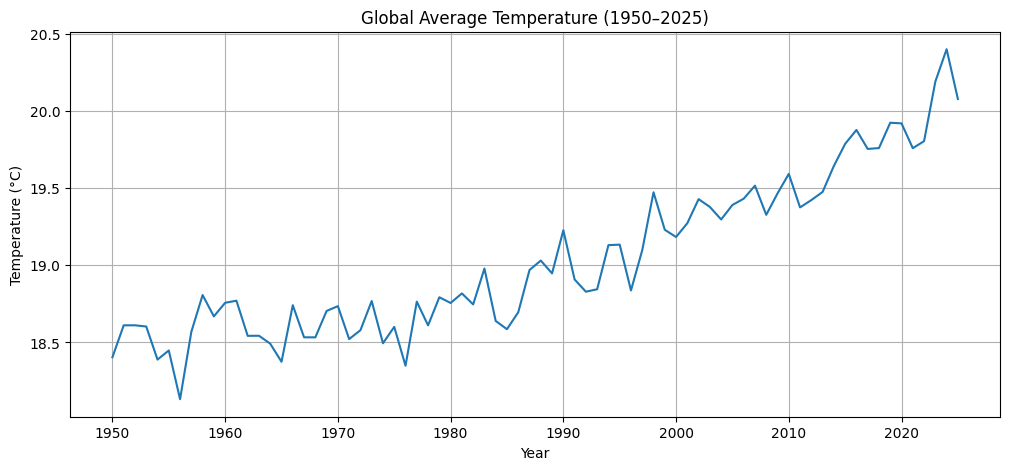

In [35]:
plt.figure(figsize=(12, 5))

plt.plot(yearly_temp.index, yearly_temp.values)

plt.title('Global Average Temperature (1950–2025)')
plt.xlabel('Year')
plt.ylabel('Temperature (°C)')
plt.grid(True)

plt.show()

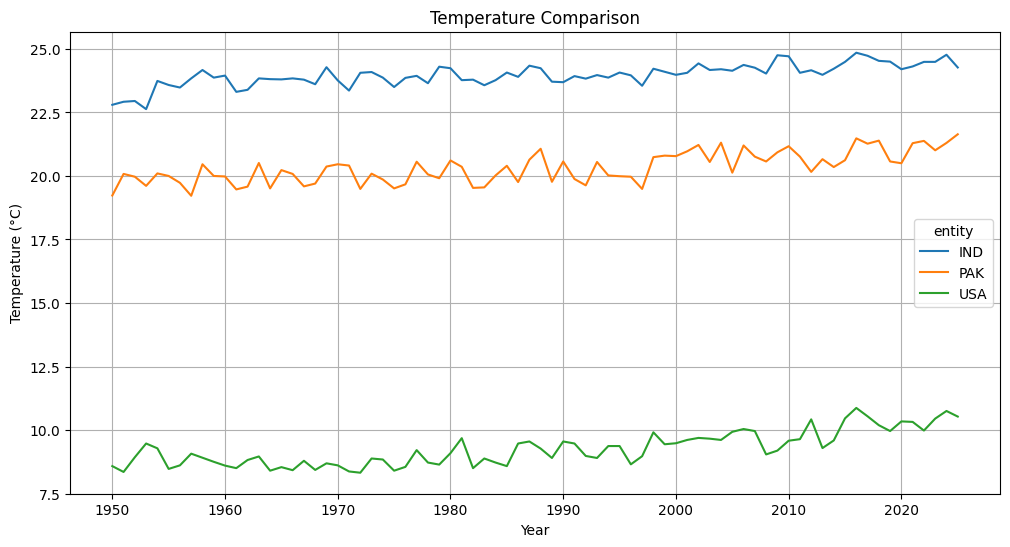

In [36]:
countries = ['PAK', 'IND', 'USA']

selected = df[df['entity'].isin(countries)]

comparison = selected.pivot(
    index='period',
    columns='entity',
    values='value'
)

comparison.plot(figsize=(12, 6))

plt.title('Temperature Comparison')
plt.xlabel('Year')
plt.ylabel('Temperature (°C)')
plt.grid(True)

plt.show()

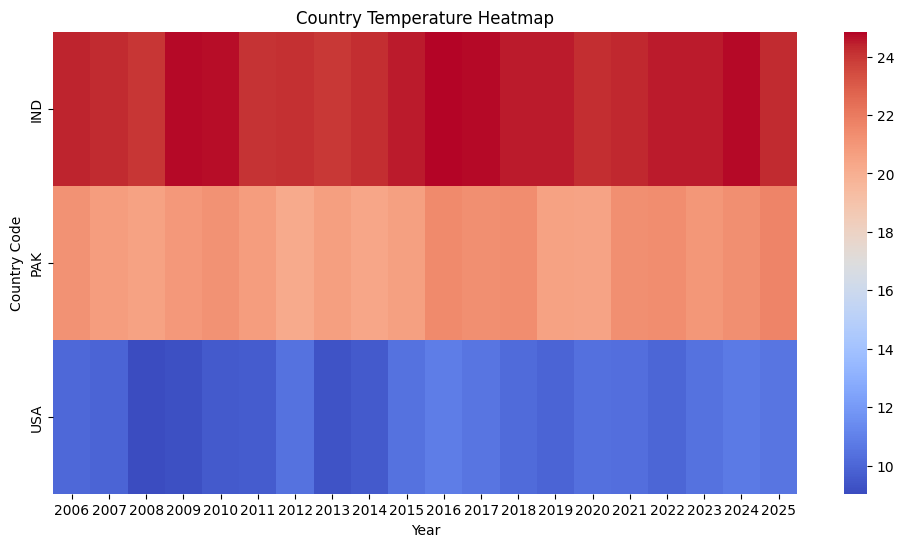

In [37]:
plt.figure(figsize=(12, 6))

sns.heatmap(
    comparison.tail(20).T,
    cmap='coolwarm',
    annot=False
)

plt.title('Country Temperature Heatmap')
plt.xlabel('Year')
plt.ylabel('Country Code')

plt.show()

In [38]:
pakistan = df[df['entity'] == 'PAK'].copy()

X = pakistan[['period']]
y = pakistan['value']

print(X.head())
print(y.head())

       period
12920    1950
12921    1951
12922    1952
12923    1953
12924    1954
12920    19.23
12921    20.08
12922    19.97
12923    19.61
12924    20.10
Name: value, dtype: float64


In [39]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, shuffle=False
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (60, 1)
Testing data: (16, 1)


In [40]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()

model.fit(X_train, y_train)

print("Model training completed!")

Model training completed!


In [41]:
predictions = model.predict(X_test)

results = pd.DataFrame({
    'Actual Temperature': y_test,
    'Predicted Temperature': predictions
})

display(results.head(10))

,Actual Temperature,Predicted Temperature
12980,21.17,20.670576
12981,20.76,20.687530
12982,20.16,20.704483
12983,20.66,20.721436
12984,20.35,20.738390
12985,20.62,20.755343
12986,21.48,20.772296
12987,21.27,20.789250
12988,21.39,20.806203
12989,20.57,20.823156


In [42]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

mae = mean_absolute_error(y_test, predictions)
mse = mean_squared_error(y_test, predictions)
r2 = r2_score(y_test, predictions)

print("MAE:", mae)
print("MSE:", mse)
print("R2 Score:", r2)

MAE: 0.3895134759655454
MSE: 0.19371080772488808
R2 Score: -0.006144950252122472
